In [1]:
import torch

In [2]:
net = torch.nn.Conv2d(1, 16, 3, 4, (3 - 1) // 2)

In [3]:
x = torch.randn(1, 1, 28, 28)
print(x.shape)

torch.Size([1, 1, 28, 28])


In [4]:
y = net(x)
print(y.shape)

torch.Size([1, 16, 7, 7])


In [ ]:
class ConvNet(torch.nn.Module):
    def __init__(self, layers=[16, 32, 64], kernel_size=3, stride=1):
        super().__init__()
        cnn_layers = []
        c1 = 1
        for c2 in layers:
            cnn_layers.append(torch.nn.Conv2d(c1, c2, kernel_size, stride, (kernel_size - 1) // 2))
            cnn_layers.append(torch.nn.ReLU())
            c1 = c2
        # Cov 1x1
        cnn_layers.append(torch.nn.Conv2d(c1, 1, kernel_size=1))
        # cnn_layers.append(torch.nn.AdaptiveAvgPool2d(1))
        self.network = torch.nn.Sequential(*cnn_layers)

    def forward(self, x):
        return self.network(x)


net = ConvNet(stride=2)

net(x).shape

torch.Size([1, 1, 4, 4])

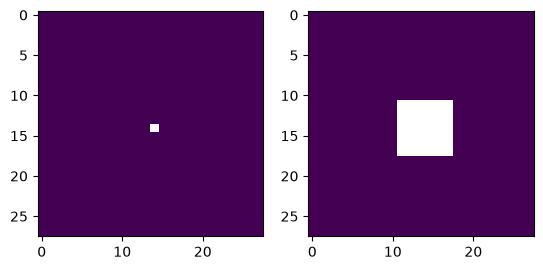

In [6]:
from matplotlib import pyplot as plt

x = torch.randn(1, 1, 28, 28, requires_grad=True)
net = ConvNet(stride=1)
y = net(x)

z = y.new_zeros(y.shape)
z[0, 0, z.shape[2] // 2, z.shape[3] // 2] = float("NaN")
f, ax = plt.subplots(1, 2)
ax[0].imshow(z[0, 0].detach().numpy())

(y * z).sum().backward()


ax[1].imshow(x.grad[0, 0].detach().numpy())